In [36]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings("ignore")

In [37]:
import os

os.listdir("/home/kniti/Downloads/MLA/Internship/Walking_Running")

['PRCP-1013-WalkRunClass.zip',
 'PRCP-1013-WalkRunClass',
 'walkrun.csv',
 'walking_running_classification.ipynb']

In [38]:
df = pd.read_csv("/home/kniti/Downloads/MLA/Internship/Walking_Running/walkrun.csv")

df.head()
df.shape
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 88588 entries, 0 to 88587
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            88588 non-null  str    
 1   time            88588 non-null  str    
 2   username        88588 non-null  str    
 3   wrist           88588 non-null  int64  
 4   activity        88588 non-null  int64  
 5   acceleration_x  88588 non-null  float64
 6   acceleration_y  88588 non-null  float64
 7   acceleration_z  88588 non-null  float64
 8   gyro_x          88588 non-null  float64
 9   gyro_y          88588 non-null  float64
 10  gyro_z          88588 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 7.4 MB


,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
count,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000
mean,0.522170,0.500801,-0.074811,-0.562585,-0.313956,0.004160,0.037203,0.022327
std,0.499511,0.500002,1.009299,0.658458,0.486815,1.253423,1.198725,1.914423
min,0.000000,0.000000,-5.350500,-3.299000,-3.753800,-4.430600,-7.464700,-9.480000
25%,0.000000,0.000000,-0.381800,-1.033500,-0.376000,-0.920700,-0.644825,-1.345125
50%,1.000000,1.000000,-0.059500,-0.759100,-0.221000,0.018700,0.039300,0.006900
75%,1.000000,1.000000,0.355500,-0.241775,-0.085900,0.888800,0.733700,1.398200
max,1.000000,1.000000,5.603300,2.668000,1.640300,4.874200,8.498000,11.266200


In [39]:
df.columns

Index(['date', 'time', 'username', 'wrist', 'activity', 'acceleration_x',
       'acceleration_y', 'acceleration_z', 'gyro_x', 'gyro_y', 'gyro_z'],
      dtype='str')

In [40]:
#Data Quality Analysis
df.isnull().sum()


date              0
time              0
username          0
wrist             0
activity          0
acceleration_x    0
acceleration_y    0
acceleration_z    0
gyro_x            0
gyro_y            0
gyro_z            0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
for col in df.columns:
    print(col, df[col].nunique())

date 12
time 88588
username 1
wrist 2
activity 2
acceleration_x 30307
acceleration_y 23957
acceleration_z 19698
gyro_x 40988
gyro_y 38957
gyro_z 51296


In [43]:
df['activity'].value_counts()



activity
1    44365
0    44223
Name: count, dtype: int64

In [44]:
df['username'].value_counts()


username
viktor    88588
Name: count, dtype: int64

In [45]:
df['wrist'].value_counts()


wrist
1    46258
0    42330
Name: count, dtype: int64

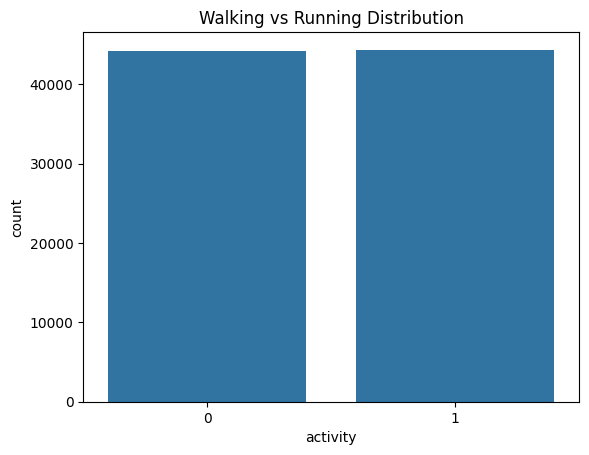

In [46]:
sns.countplot(data=df, x='activity')
plt.title("Walking vs Running Distribution")
plt.show()

In [47]:
pd.crosstab(df['username'], df['activity'])

activity,0,1
username,,
viktor,44223,44365


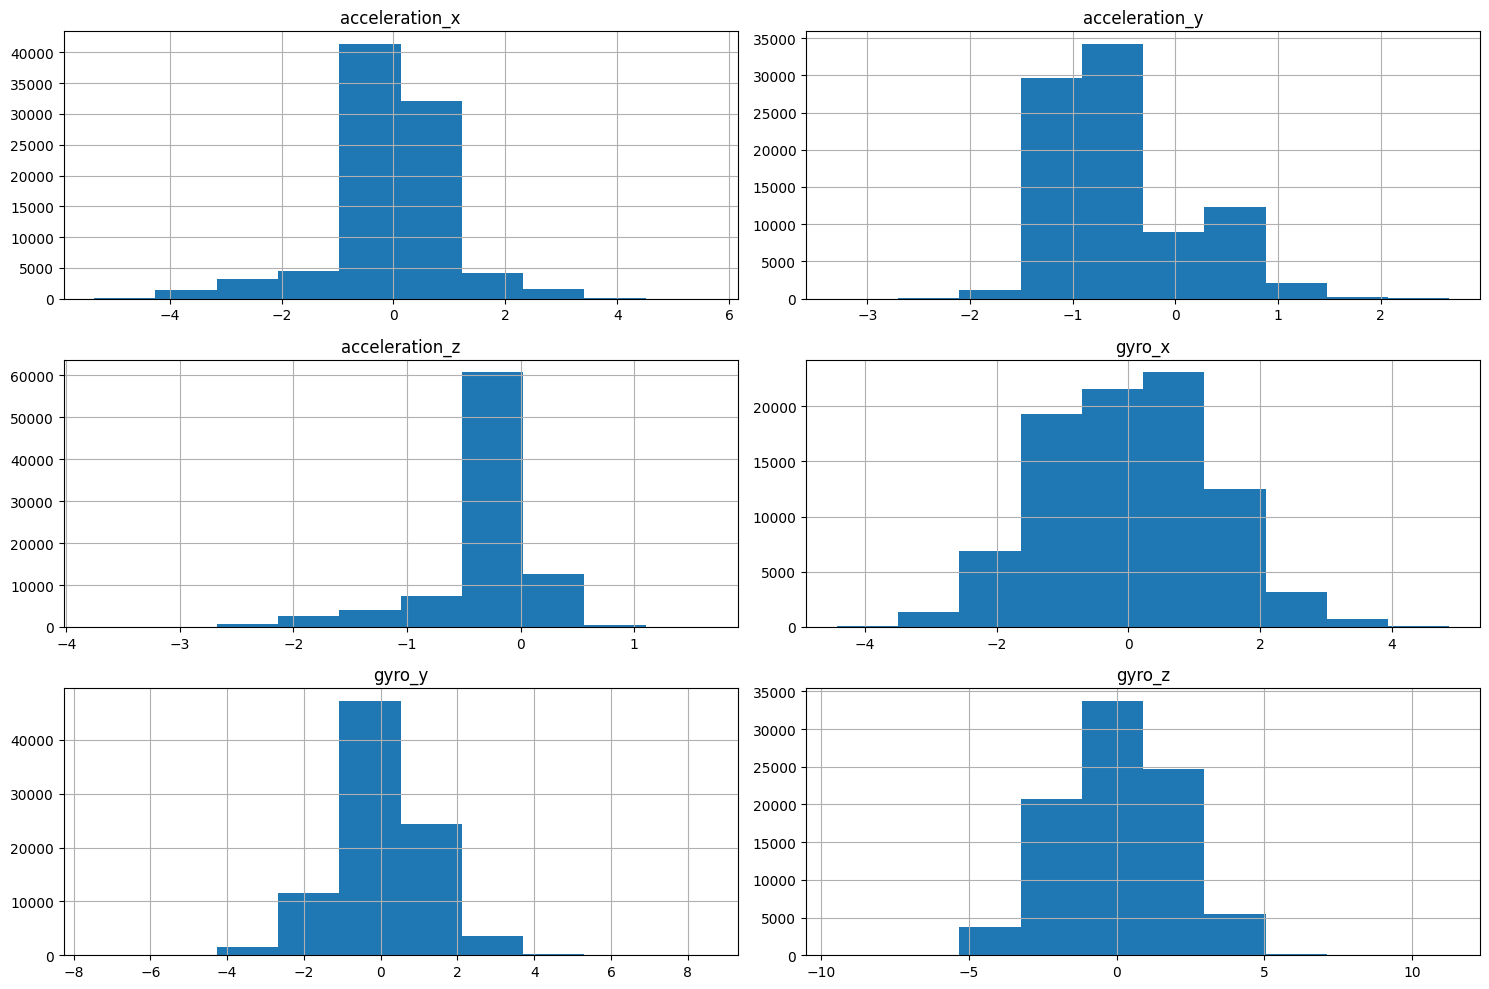

In [48]:
#Acceleration vs Gyroscope
sensor_cols = [
    'acceleration_x',
    'acceleration_y',
    'acceleration_z',
    'gyro_x',
    'gyro_y',
    'gyro_z'
]

df[sensor_cols].hist(figsize=(15,10))
plt.tight_layout()
plt.show()

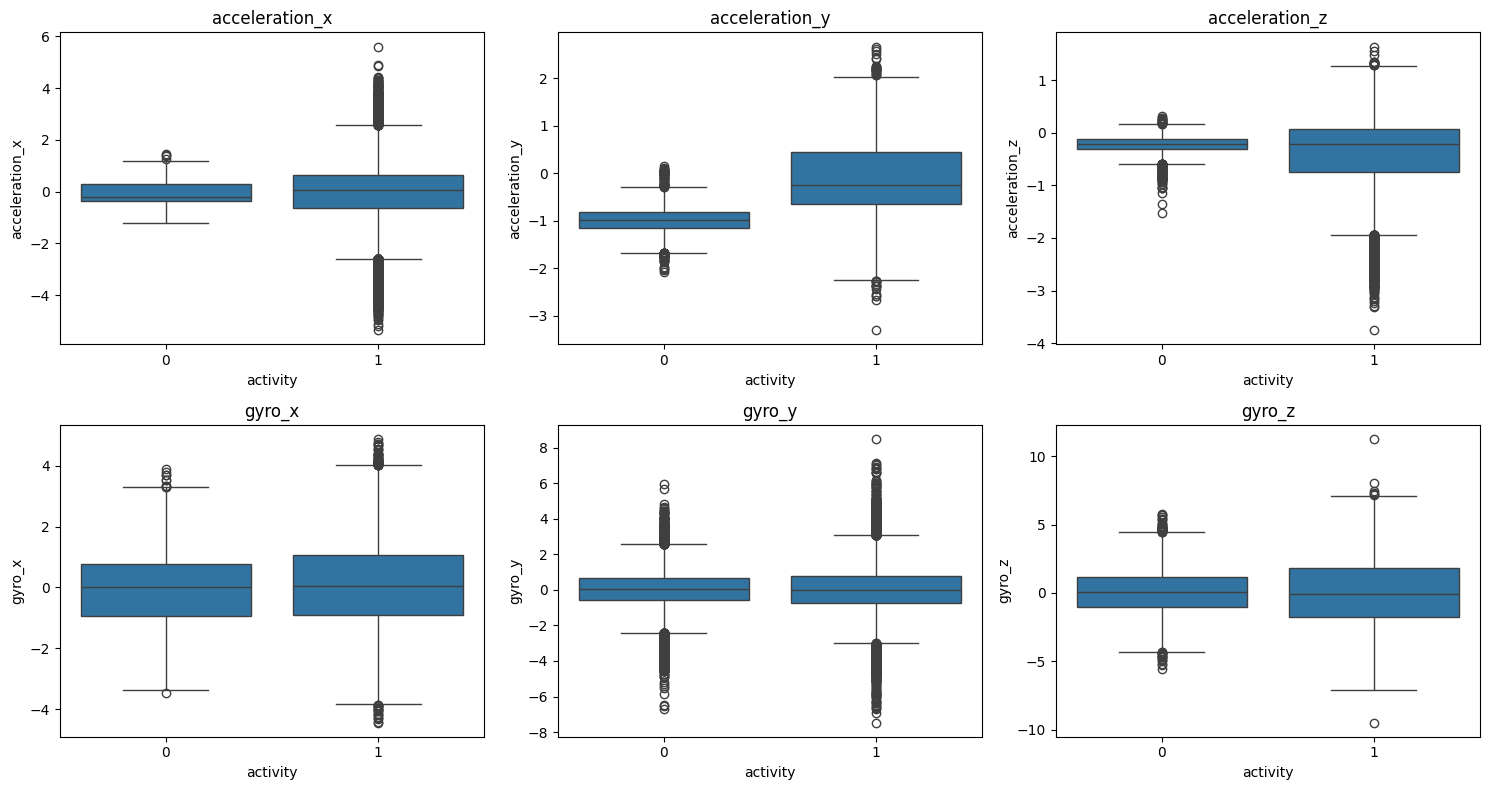

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(15,8))

for ax, col in zip(axes.flatten(), sensor_cols):
    sns.boxplot(data=df, x='activity', y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()

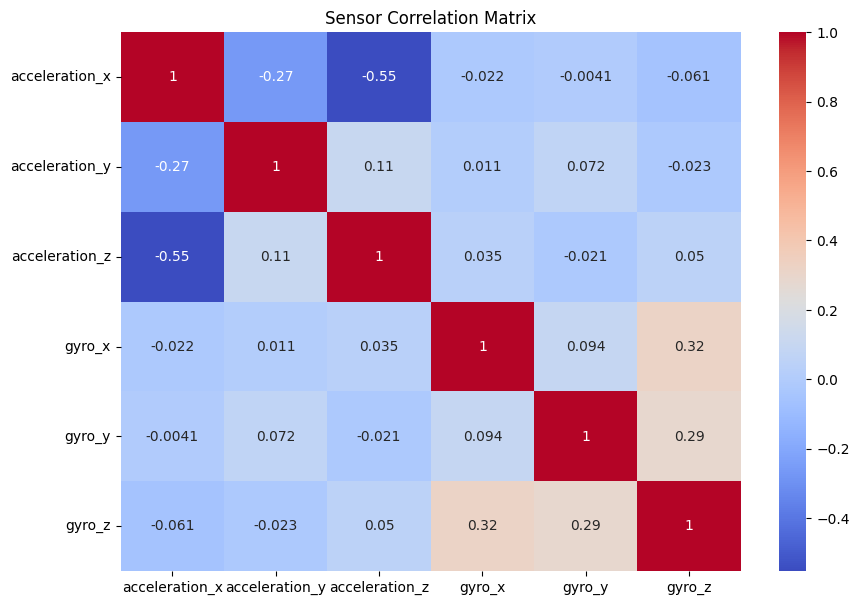

In [50]:
#Correlation Analysis
corr = df[sensor_cols].corr()

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Sensor Correlation Matrix")
plt.show()

In [51]:
train_test_split(df)

[            date                time username  wrist  activity  \
 53167  2017-7-17   20:4:39:885194003   viktor      1         1   
 83157   2017-7-9   19:49:5:701135993   viktor      0         1   
 44168  2017-7-17  16:12:29:961323976   viktor      0         0   
 33990  2017-7-16  14:59:55:603600025   viktor      1         0   
 81137   2017-7-9    19:42:53:6398022   viktor      0         1   
 ...          ...                 ...      ...    ...       ...   
 22835  2017-7-15    18:9:37:42051017   viktor      1         1   
 14315  2017-7-11   18:3:55:469137012   viktor      1         1   
 48896  2017-7-17  19:55:31:619316995   viktor      1         1   
 12244  2017-7-11  17:56:52:868408024   viktor      1         1   
 37987  2017-7-16  15:19:56:897840023   viktor      1         0   
 
        acceleration_x  acceleration_y  acceleration_z  gyro_x  gyro_y  gyro_z  
 53167          0.3665          0.5943         -0.0547 -0.3664  0.6136  0.1063  
 83157         -0.3166         -

In [52]:
#we are going to use logistic regression, svm, gradient boosting

scaler = StandardScaler()
features = [
    'acceleration_x',
    'acceleration_y',
    'acceleration_z',
    'gyro_x',
    'gyro_y',
    'gyro_z',
]

X = df[features]
y = df['activity']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [53]:
#log reg

from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)

log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

from sklearn.metrics import accuracy_score

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_lr))


Logistic Regression Accuracy: 0.854893328818151
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      8845
           1       0.89      0.81      0.85      8873

    accuracy                           0.85     17718
   macro avg       0.86      0.85      0.85     17718
weighted avg       0.86      0.85      0.85     17718



In [54]:
#svm

from sklearn.svm import SVC

svm = SVC(
    kernel='rbf',
    random_state=42
)

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9866802122135682
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      8845
           1       0.99      0.98      0.99      8873

    accuracy                           0.99     17718
   macro avg       0.99      0.99      0.99     17718
weighted avg       0.99      0.99      0.99     17718



In [55]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)

gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))


Gradient Boosting Accuracy: 0.9843661812845693
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      8845
           1       0.99      0.98      0.98      8873

    accuracy                           0.98     17718
   macro avg       0.98      0.98      0.98     17718
weighted avg       0.98      0.98      0.98     17718



In [56]:
df['activity'].value_counts()

activity
1    44365
0    44223
Name: count, dtype: int64

In [57]:
print(y_pred_lr)
print(y_pred_svm)
print(y_pred_gb)

[0 0 1 ... 1 0 0]
[0 0 1 ... 1 0 0]
[0 0 1 ... 1 0 0]


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

models_predictions = {
    'Logistic Regression': y_pred_lr,
    'SVM': y_pred_svm,
    'Gradient Boosting': y_pred_gb
}

for model_name, y_pred in models_predictions.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1 Score': f1_score(y_test, y_pred, average='weighted')
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.854893,0.857467,0.854893,0.854643
1,SVM,0.986680,0.986742,0.986680,0.986680
2,Gradient Boosting,0.984366,0.984420,0.984366,0.984366


In [59]:
print("Logistic Regression")
print(classification_report(y_test, y_pred_lr))

print("SVM")
print(classification_report(y_test, y_pred_svm))

print("Gradient Boosting")
print(classification_report(y_test, y_pred_gb))


Logistic Regression
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      8845
           1       0.89      0.81      0.85      8873

    accuracy                           0.85     17718
   macro avg       0.86      0.85      0.85     17718
weighted avg       0.86      0.85      0.85     17718

SVM
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      8845
           1       0.99      0.98      0.99      8873

    accuracy                           0.99     17718
   macro avg       0.99      0.99      0.99     17718
weighted avg       0.99      0.99      0.99     17718

Gradient Boosting
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      8845
           1       0.99      0.98      0.98      8873

    accuracy                           0.98     17718
   macro avg       0.98      0.98      0.98     17718
weighted avg       0.98      0.9

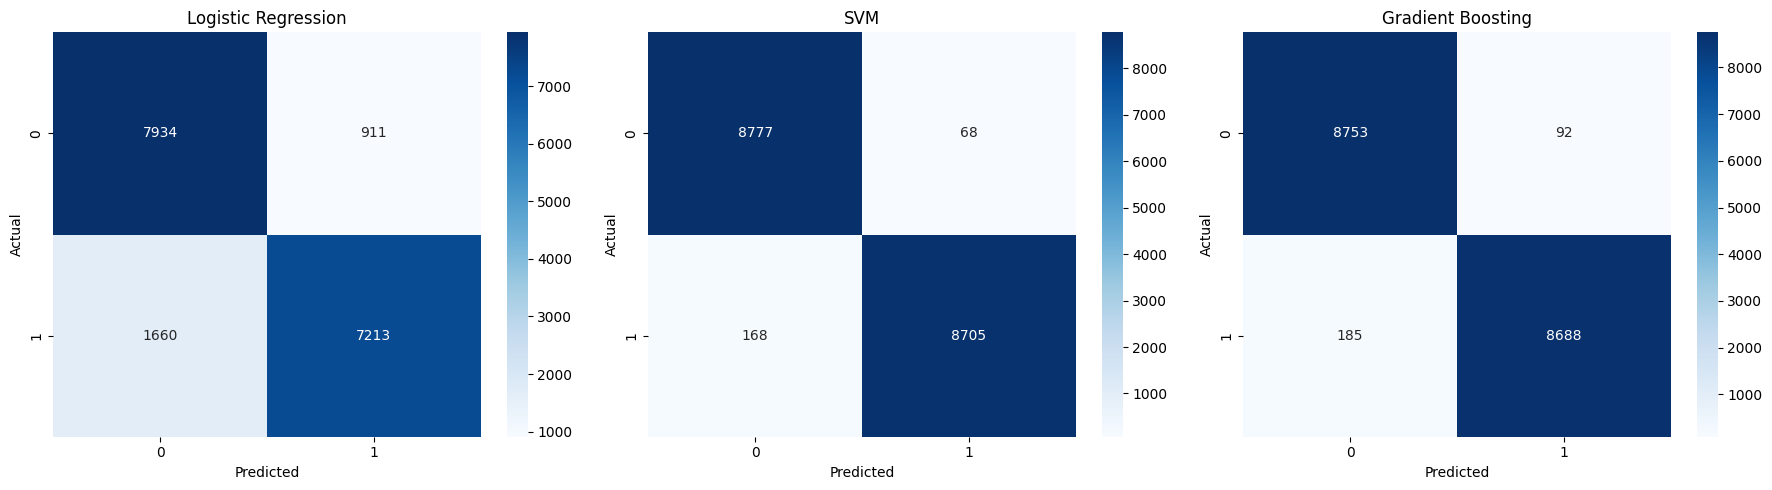

In [60]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

predictions = {
    'Logistic Regression': y_pred_lr,
    'SVM': y_pred_svm,
    'Gradient Boosting': y_pred_gb
}

for ax, (model_name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:
svm = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)

from sklearn.metrics import roc_auc_score

positive_class = 1

lr_running_prob = log_reg.predict_proba(X_test_scaled)[
    :, list(log_reg.classes_).index(positive_class)
]

svm_running_prob = svm.predict_proba(X_test_scaled)[
    :, list(svm.classes_).index(positive_class)
]

gb_running_prob = gb.predict_proba(X_test)[
    :, list(gb.classes_).index(positive_class)
]

print(
    "Logistic Regression ROC-AUC:",
    roc_auc_score(y_test == positive_class, lr_running_prob)
)

print(
    "SVM ROC-AUC:",
    roc_auc_score(y_test == positive_class, svm_running_prob)
)

print(
    "Gradient Boosting ROC-AUC:",
    roc_auc_score(y_test == positive_class, gb_running_prob)
)



Logistic Regression ROC-AUC: 0.9298915281953999
SVM ROC-AUC: 0.9987855765329197
Gradient Boosting ROC-AUC: 0.9983216020400173


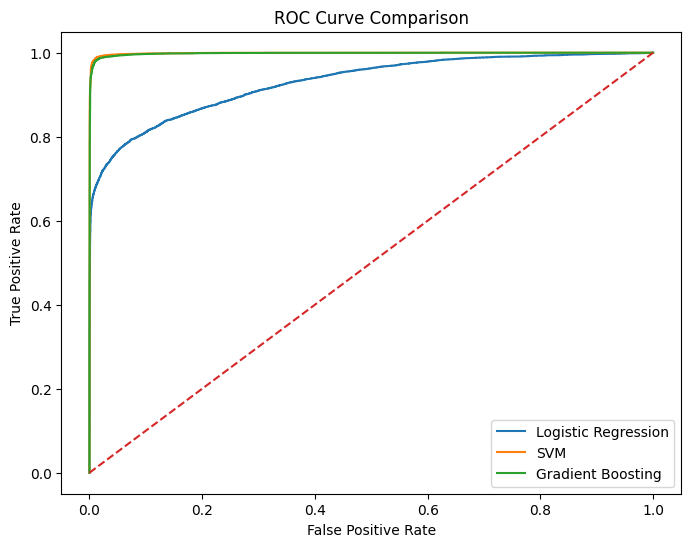

In [62]:
from sklearn.metrics import roc_curve

y_test_binary = (y_test == positive_class).astype(int)

fpr_lr, tpr_lr, _ = roc_curve(y_test_binary, lr_running_prob)
fpr_svm, tpr_svm, _ = roc_curve(y_test_binary, svm_running_prob)
fpr_gb, tpr_gb, _ = roc_curve(y_test_binary, gb_running_prob)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label='Logistic Regression')
plt.plot(fpr_svm, tpr_svm, label='SVM')
plt.plot(fpr_gb, tpr_gb, label='Gradient Boosting')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.show()

In [63]:
results_df['ROC-AUC'] = [
    roc_auc_score(y_test_binary, lr_running_prob),
    roc_auc_score(y_test_binary, svm_running_prob),
    roc_auc_score(y_test_binary, gb_running_prob)
]

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.854893,0.857467,0.854893,0.854643,0.929892
1,SVM,0.986680,0.986742,0.986680,0.986680,0.998786
2,Gradient Boosting,0.984366,0.984420,0.984366,0.984366,0.998322


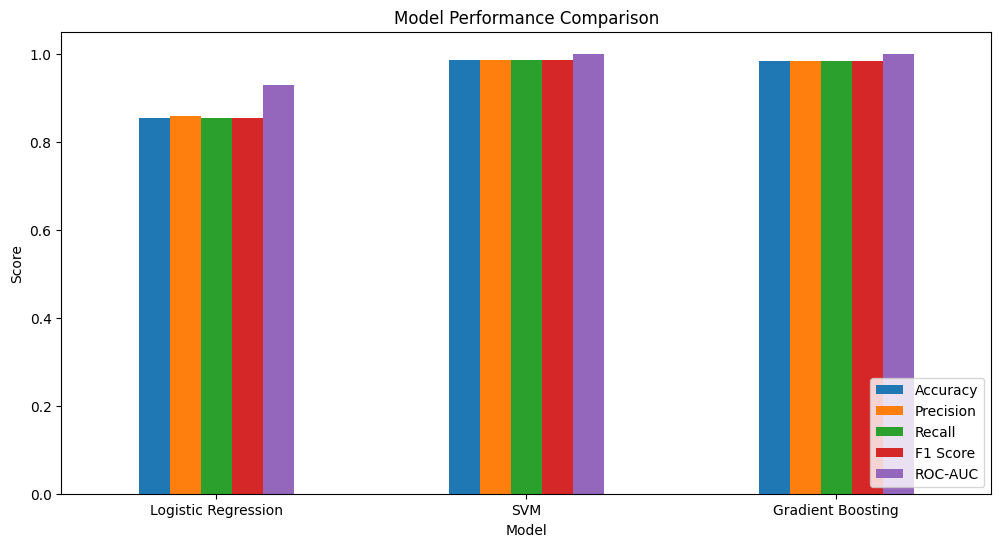

In [64]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC-AUC'
]

results_plot = results_df.set_index('Model')[metrics]

results_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')

plt.show()

In [65]:
#feature importance in svm

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': gb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
1,acceleration_y,0.596443
2,acceleration_z,0.311955
0,acceleration_x,0.054932
5,gyro_z,0.033341
3,gyro_x,0.002604
4,gyro_y,0.000725


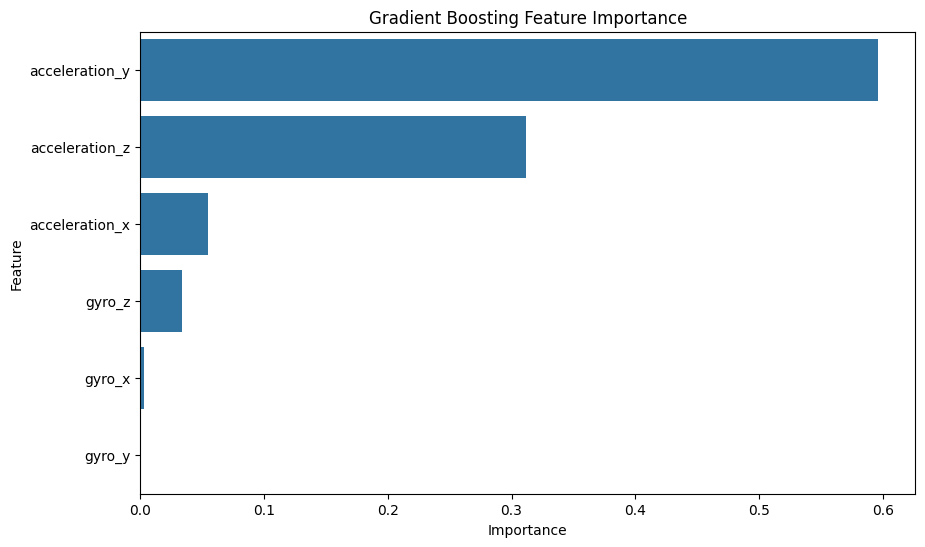

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Gradient Boosting Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [67]:
#log reg coefficients

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': log_reg.coef_[0]
})

coefficients['Absolute_Coefficient'] = (
    coefficients['Coefficient'].abs()
)

coefficients = coefficients.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

coefficients

,Feature,Coefficient,Absolute_Coefficient
1,acceleration_y,4.523709,4.523709
2,acceleration_z,-1.186437,1.186437
0,acceleration_x,0.485692,0.485692
5,gyro_z,0.257944,0.257944
4,gyro_y,-0.190093,0.190093
3,gyro_x,-0.022913,0.022913


In [76]:
positive_class = 1

y_test_binary = (y_test == positive_class).astype(int)

running_index_lr = list(log_reg.classes_).index(positive_class)

lr_prob = log_reg.predict_proba(X_test_scaled)[:, running_index_lr]

svm = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)

running_index_svm = list(svm.classes_).index(positive_class)

svm_prob = svm.predict_proba(X_test_scaled)[:, running_index_svm]

running_index_gb = list(gb.classes_).index(positive_class)

gb_prob = gb.predict_proba(X_test)[:, running_index_gb]

from sklearn.metrics import roc_curve, roc_auc_score

fpr_lr, tpr_lr, _ = roc_curve(y_test_binary, lr_prob)
fpr_svm, tpr_svm, _ = roc_curve(y_test_binary, svm_prob)
fpr_gb, tpr_gb, _ = roc_curve(y_test_binary, gb_prob)

auc_lr = roc_auc_score(y_test_binary, lr_prob)
auc_svm = roc_auc_score(y_test_binary, svm_prob)
auc_gb = roc_auc_score(y_test_binary, gb_prob)

print("Logistic Regression AUC:", auc_lr)
print("SVM AUC:", auc_svm)
print("Gradient Boosting AUC:", auc_gb)

inal_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_gb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, average='weighted'),
        precision_score(y_test, y_pred_svm, average='weighted'),
        precision_score(y_test, y_pred_gb, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_svm, average='weighted'),
        recall_score(y_test, y_pred_gb, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_svm, average='weighted'),
        f1_score(y_test, y_pred_gb, average='weighted')
    ],
    'ROC-AUC': [
        auc_lr,
        auc_svm,
        auc_gb
    ]
})


Logistic Regression AUC: 0.9298915281953999
SVM AUC: 0.9987855765329197
Gradient Boosting AUC: 0.9983216020400173


In [77]:
final_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_gb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, average='weighted'),
        precision_score(y_test, y_pred_svm, average='weighted'),
        precision_score(y_test, y_pred_gb, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_svm, average='weighted'),
        recall_score(y_test, y_pred_gb, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_svm, average='weighted'),
        f1_score(y_test, y_pred_gb, average='weighted')
    ],
    'ROC-AUC': [
        auc_lr,
        auc_svm,
        auc_gb
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.854893,0.857467,0.854893,0.854643,0.929892
1,SVM,0.986680,0.986742,0.986680,0.986680,0.998786
2,Gradient Boosting,0.984366,0.984420,0.984366,0.984366,0.998322


In [80]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.854893,0.857467,0.854893,0.854643,0.929892
1,SVM,0.986680,0.986742,0.986680,0.986680,0.998786
2,Gradient Boosting,0.984366,0.984420,0.984366,0.984366,0.998322


NameError: name 'y_pred_lr_tuned' is not defined

#Challenge 1 — Different feature scales
#The accelerometer and gyroscope variables can have different numerical ranges.
#Technique used: StandardScaler
#Reason: Logistic Regression and SVM can be affected by feature scale. Standardization puts the features on a comparable scale.
#Challenge 2 — Sensor noise
#Motion sensors can contain fluctuations caused by natural hand/wrist movement.
#Technique used: Exploratory analysis and feature engineering.
#Reason: Examining distributions, outliers and sensor magnitudes helps the model distinguish meaningful movement patterns from individual noisy readings.
#Challenge 3 — Class distribution
#Walking and Running may not have exactly the same number of observations.
#Technique used: Stratified train/test split and F1-score-based evaluation.


Challenge 4 — Multiple sensor dimensions
The dataset contains six raw sensor measurements:
acceleration_x
acceleration_y
acceleration_z
gyro_x
gyro_y
gyro_z

Technique used: Feature analysis and, where applicable, derived sensor features such as magnitude.
Reason: Movement occurs across multiple axes, so considering the combined sensor information can provide a more useful representation of activity.
Challenge 5 — Model parameter selection
Default parameters may not provide the best performance.
Technique used: GridSearchCV with 5-fold cross-validation.
Reason: It systematically evaluates different hyperparameter combinations and selects the combination giving the best cross-validation F1 score.
Challenge 6 — Choosing appropriate evaluation metrics
Accuracy alone does not explain the type of classification errors.
Technique used: Accuracy, Precision, Recall, F1-score, Confusion Matrix and ROC-AUC.
Reason: These metrics provide a more complete assessment of Walking vs Running classification.
Challenge 7 — Possible time/user dependency
Sensor readings collected close together can be highly related, and readings from the same user can have similar movement characteristics.
Technique used: Investigation of timestamp and user information, with group-aware validation considered where appropriate.
Reason: A purely random row-level split can potentially place very similar observations in both training and testing sets and produce overly optimistic performance.